In [1]:
import numpy as np
import numpy as np
from scipy import special
from scipy.special import erfc, erfi
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.optimize import curve_fit
from scipy.special import erfc, erfcx, erf
from cdm_ewald.CDM_Ewald_direct import CDM_Ewald_direct

In [2]:
# HEDA parameters and derivation of permittivity from HEDA parameters
# 9.5 nm nc
df_heda = pd.read_excel("heda_parameters.xlsx")
df_heda

,diameter(nm),ne(10^26m^-3),n_std,volume_fraction_electron_core,depletion_layer_thickness(nm),mean_free_path(nm)
0,9.5,3.420,0.447,0.470,1.057,17.00
1,13.0,2.968,0.160,0.546,1.211,7.10
2,21.0,3.419,0.488,0.736,1.046,5.22
3,26.0,3.324,0.725,0.820,0.845,4.56


In [3]:
def HEDA_conversion(
    nc_diameter,
    ne,
    depletion_layer_thickness,
    bulk_mean_free_path,
):
    """
    Convert HEDA parameters to effective electron mass,
    plasma frequency, and damping coefficient.

    Parameters
    ----------
    nc_diameter : float
        Nanocrystal diameter [m].
    ne : float
        Electron density [m^-3].
    depletion_layer_thickness : float
        Depletion layer thickness [m].
    bulk_mean_free_path : float
        Bulk electron mean free path [m].

    Returns
    -------
    electron_mass_ratio : float
        Effective electron mass divided by free electron mass.
    plasma_frequency : float
        Plasma angular frequency [rad/s].
    damping_coefficient : float
        Drude damping coefficient [s^-1].
    """

    # Physical constants (SI)
    hbar = 1.054571817e-34          # J s
    electron_charge = 1.602176634e-19  # C
    electron_mass = 9.1093837e-31  # kg
    vacuum_permittivity = 8.8541878128e-12  # F/m
    speed_of_light_cm = 2.998e10 # cm/s
    # Effective nanocrystal radius
    nc_radius = nc_diameter / 2
    effective_radius = nc_radius - depletion_layer_thickness

    if np.any(effective_radius <= 0):
        raise ValueError(
        "Depletion layer thickness must be smaller than the nanocrystal radius."
    )

    # Effective electron mass
    effective_electron_mass = 0.4 * electron_mass

    # Plasma frequency
    plasma_frequency = np.sqrt(
        ne * electron_charge**2
        / (vacuum_permittivity * effective_electron_mass)
    ) / (2*np.pi*speed_of_light_cm)

    # Damping coefficient
    damping_coefficient = (hbar/effective_electron_mass) * (3*np.pi**2*ne)**(1/3) * (
        1 / bulk_mean_free_path
        + 3 / (4 * effective_radius)
    ) / (2*np.pi*speed_of_light_cm)


    return plasma_frequency, damping_coefficient

In [4]:
df_heda["plasma_frequency(cm^-1)"], df_heda["damping_coefficient(cm^-1)"] = HEDA_conversion(
    df_heda["diameter(nm)"]*1e-9,
    df_heda["ne(10^26m^-3)"]*1e26,
    df_heda["depletion_layer_thickness(nm)"]*1e-9,
    df_heda["mean_free_path(nm)"]*1e-9,
)

In [5]:
df_heda

,diameter(nm),ne(10^26m^-3),n_std,volume_fraction_electron_core,depletion_layer_thickness(nm),mean_free_path(nm),plasma_frequency(cm^-1),damping_coefficient(cm^-1)
0,9.5,3.420,0.447,0.470,1.057,17.00,8757.156105,870.597750
1,13.0,2.968,0.160,0.546,1.211,7.10,8157.967800,896.171531
2,21.0,3.419,0.488,0.736,1.046,5.22,8755.875725,900.399406
3,26.0,3.324,0.725,0.820,0.845,4.56,8633.373820,925.233321


In [41]:
# write code for first sample
idx = 0
r_nc = df_heda["diameter(nm)"][idx] / 2
depletion_layer_thickness = df_heda["depletion_layer_thickness(nm)"][idx]
eta = df_heda["volume_fraction_electron_core"][idx] + 0.4
plasma_freq = df_heda["plasma_frequency(cm^-1)"][idx]
damping_coef = df_heda["damping_coefficient(cm^-1)"][idx]
gap = 1.4 # nm
eps_vacuum = 1 # vacuum/air
eps_il = 2.02 # ionic liquid
eps_inf = 4 # indium oxide
eps_substrate = 2.07 # CaF2
light_freq_min = 1000
light_freq_max = 5000
light_freq_intv = 100
light_freq_list = np.arange(light_freq_min,light_freq_max,light_freq_intv)
# convert to wavelength in vacuum/air and angular wavenumber in the medium
wavelength_nm = 10**7/light_freq_list
# angular wavenumber list in the unit of cm^-1 (angular wavenumber in the medium, which is ionic liquid)
k_real_list = 2*np.pi*light_freq_list*np.sqrt(eps_il)
# wavenumber list in the unit of 1/particle radius first convert to m^-1 then convert to 1/particle radius
k_dimensionless_list = k_real_list*r_nc*1e-7 # 1e-7 is to convert nm to cm
# permittivity core-shell
eps_core = eps_inf - plasma_freq**2 / (light_freq_list**2 + 1j*damping_coef*light_freq_list)
eps_shell = eps_inf
eps_p = eps_shell*(eps_core+2*eps_shell+2*eta*(eps_core-eps_shell))/(eps_core+2*eps_shell-eta*(eps_core-eps_shell))
# polarizability in unit of r_nc^3, add 4pi for consistency
polarizability_list = 4*np.pi*(eps_p-eps_il)/(eps_p+2*eps_il)
# define lattice
lattice_type = "hexagonal"

lattice_constant = (r_nc*2+gap)/r_nc
layer_separation = lattice_constant
num_layer = 11
position_list = []
rng = np.random.default_rng()

max_shift = 0.5* lattice_constant



for i in range(num_layer):
    layer_shifts = rng.uniform(
        low=-max_shift,
        high=max_shift,
        size=(2)
    )
    position_list.append([layer_shifts[0],layer_shifts[1],-i*layer_separation])
positions = np.array(position_list)
incident_theta_air = np.pi/3 # 60 degree from air/vacuum
incident_theta_il = np.arcsin(np.sin(incident_theta_air)*np.sqrt(eps_vacuum/eps_il)) # refraction angle in the ionic liquid, which is the true incident angle to the metasurface
print(f"incident angle from il is {incident_theta_il*180/np.pi} degree")
wavevector_direction = np.array([np.sin(incident_theta_il),0,-np.cos(incident_theta_il)]) # z
polarization_direction = np.array([np.cos(incident_theta_il),0,np.sin(incident_theta_il)]) # x
if lattice_type == "square":
    v1 = np.array([lattice_constant, 0.0])
    v2 = np.array([0.0, lattice_constant])
    lattice_vectors = np.stack((v1,v2),axis=1)
elif lattice_type == "hexagonal":
    v1 = np.array([lattice_constant, 0.0])
    v2 = np.array([0.5 * lattice_constant, np.sqrt(3) * lattice_constant / 2])
    lattice_vectors = np.stack((v1,v2),axis=1)
cdm = CDM_Ewald_direct(lattice_vectors,positions,polarizability_list,k_dimensionless_list, wavevector_direction,polarization_direction)

incident angle from il is 37.54131526382355 degree
[[ 0.00258466  0.         -0.00336338]
 [ 0.00284313  0.         -0.00369971]
 [ 0.0031016   0.         -0.00403605]
 [ 0.00336006  0.         -0.00437239]
 [ 0.00361853  0.         -0.00470873]
 [ 0.003877    0.         -0.00504506]
 [ 0.00413546  0.         -0.0053814 ]
 [ 0.00439393  0.         -0.00571774]
 [ 0.0046524   0.         -0.00605408]
 [ 0.00491086  0.         -0.00639041]
 [ 0.00516933  0.         -0.00672675]
 [ 0.00542779  0.         -0.00706309]
 [ 0.00568626  0.         -0.00739943]
 [ 0.00594473  0.         -0.00773576]
 [ 0.00620319  0.         -0.0080721 ]
 [ 0.00646166  0.         -0.00840844]
 [ 0.00672013  0.         -0.00874478]
 [ 0.00697859  0.         -0.00908111]
 [ 0.00723706  0.         -0.00941745]
 [ 0.00749553  0.         -0.00975379]
 [ 0.00775399  0.         -0.01009013]
 [ 0.00801246  0.         -0.01042646]
 [ 0.00827093  0.         -0.0107628 ]
 [ 0.00852939  0.         -0.01109914]
 [ 0.00878786

In [42]:
positions

array([[ -0.08658004,   0.64029629,   0.        ],
       [  0.62942548,  -0.3452273 ,  -2.29473684],
       [ -0.23778564,   0.48207387,  -4.58947368],
       [ -0.80285539,  -0.19111268,  -6.88421053],
       [ -0.58358203,  -0.74261653,  -9.17894737],
       [  0.98269543,   0.11922493, -11.47368421],
       [  1.04986928,   0.36761848, -13.76842105],
       [ -0.39346237,  -0.26383856, -16.06315789],
       [  0.45279283,  -0.88882641, -18.35789474],
       [  0.8119155 ,  -1.02598704, -20.65263158],
       [ -0.4894325 ,  -1.09825104, -22.94736842]])

In [43]:
cdm.compute()

run for 0
G [[ 2.46077620e-02+3.68760305e-04j -5.14930259e-04+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j ... -2.88160238e-05+3.67636758e-04j
  -7.53016237e-64+1.06228051e-65j  2.21443443e-05-2.82519025e-04j]
 [-5.14930259e-04+0.00000000e+00j  4.96650810e-02+5.86534530e-04j
   0.00000000e+00+0.00000000e+00j ... -7.53016237e-64+1.06228051e-65j
  -4.58333607e-05+5.84745080e-04j  6.23530760e-63-5.11570797e-65j]
 [ 0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
  -7.42755606e-02+2.17770176e-04j ...  2.21443443e-05-2.82519025e-04j
   6.23530760e-63-5.11570797e-65j -1.70173369e-05+2.17108322e-04j]
 ...
 [-2.80503669e-05+3.67695969e-04j -7.53016237e-64-1.06228051e-65j
  -2.15559575e-05+2.82564527e-04j ...  2.46077620e-02+3.68760305e-04j
  -5.14930259e-04+0.00000000e+00j  0.00000000e+00+0.00000000e+00j]
 [-7.53016237e-64-1.06228051e-65j -4.46155443e-05+5.84839259e-04j
   6.23530760e-63+5.11570797e-65j ... -5.14930259e-04+0.00000000e+00j
   4.96650810e-02+5.86534530e-04j  

dips.shape (40, 11, 3)


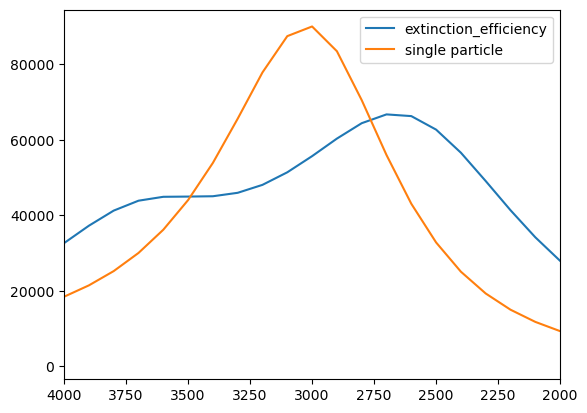

In [44]:
# postprocessing and compute transmission and extinction
print(f"dips.shape {cdm.dips.shape}")
# first compute extinction

# plt.plot(light_freq_list,light_freq_list*np.imag(cdm.dips[:,0,0]),label='xaxis')
# plt.plot(light_freq_list,light_freq_list*np.imag(cdm.dips[:,0,2]),label='zaxis')
plt.plot(light_freq_list, 1000000*cdm.extinction_efficiency/num_layer,label="extinction_efficiency")
plt.plot(light_freq_list,light_freq_list*np.imag(polarizability_list),label='single particle')

plt.xlim(4000,2000)
plt.legend()
plt.show()

In [45]:
peak_idx = np.argmax(cdm.extinction_efficiency)
dips = cdm.dips[peak_idx,:,:]
dips.shape

(11, 3)

In [46]:
polarizability_list[peak_idx]

(19.322374870134364+20.741240275823287j)

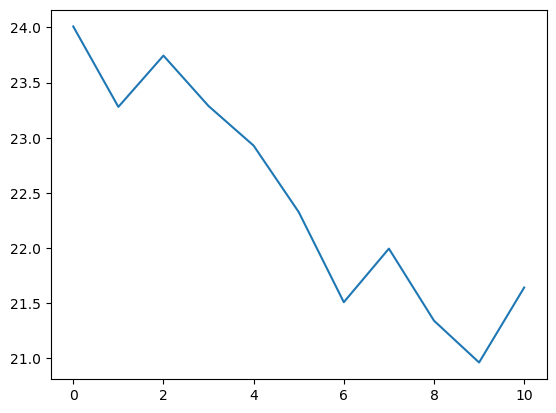

In [47]:
plt.plot(np.linalg.norm(np.abs(dips),axis=1))

In [48]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
def plot_dips_interactive(positions, dips, scale=1.0):
    positions = np.asarray(positions)
    dips = np.asarray(dips)

    # common normalization for real/imag
    max_mag = max(
        np.max(np.linalg.norm(np.real(dips), axis=1)),
        np.max(np.linalg.norm(np.imag(dips), axis=1))
    )

    # characteristic spacing
    d = positions[:, None, :] - positions[None, :, :]
    dist = np.linalg.norm(d, axis=2)
    dist[dist == 0] = np.inf
    nn = np.min(dist)

    vector_scale = scale * nn / max_mag

    real_dips = np.real(dips) * vector_scale
    imag_dips = np.imag(dips) * vector_scale

    # ---------- REAL ----------
    fig1 = plt.figure(figsize=(7, 6))
    ax1 = fig1.add_subplot(111, projection="3d")

    ax1.scatter(
        positions[:, 0],
        positions[:, 1],
        positions[:, 2],
        s=50
    )

    ax1.quiver(
        positions[:, 0],
        positions[:, 1],
        positions[:, 2],
        real_dips[:, 0],
        real_dips[:, 1],
        real_dips[:, 2],
        normalize=False,
        arrow_length_ratio=0.18,
        linewidth=1.5
    )

    ax1.set_title(r"Real part: $\mathrm{Re}(\mathbf p)$")
    ax1.set_xlabel("x")
    ax1.set_ylabel("y")
    ax1.set_zlabel("z")
    ax1.set_box_aspect((1, 1, 1))

    # ---------- IMAG ----------
    fig2 = plt.figure(figsize=(7, 6))
    ax2 = fig2.add_subplot(111, projection="3d")

    ax2.scatter(
        positions[:, 0],
        positions[:, 1],
        positions[:, 2],
        s=50
    )

    ax2.quiver(
        positions[:, 0],
        positions[:, 1],
        positions[:, 2],
        imag_dips[:, 0],
        imag_dips[:, 1],
        imag_dips[:, 2],
        normalize=False,
        arrow_length_ratio=0.18,
        linewidth=1.5
    )

    ax2.set_title(r"Imaginary part: $\mathrm{Im}(\mathbf p)$")
    ax2.set_xlabel("x")
    ax2.set_ylabel("y")
    ax2.set_zlabel("z")
    ax2.set_box_aspect((1, 1, 1))

    plt.show()
plot_dips_interactive(
    positions,
    dips,
    scale=1.5
)

ValueError: 
\mathrm{Im}(\mathbf p)
            ^
ParseFatalException: Unknown symbol: \mathbf, found '\'  (at char 12), (line:1, col:13)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous view', 'arrow-left', 'back'), ('Forward', 'Forward to next view', 'arrow-right', 'forward'), ('Pan', 'Left button pans, Right button zooms\nx/y fixes axis, CTRL fixes aspect', 'arrows', 'pan'), ('Zoom', 'Zoom to rectangle\nx/y fixes axis', 'square-o', 'zoom'), ('Download', 'Download plot', 'floppy-o', 'save_figure')]))

ValueError: 
\mathrm{Re}(\mathbf p)
            ^
ParseFatalException: Unknown symbol: \mathbf, found '\'  (at char 12), (line:1, col:13)

Canvas(toolbar=Toolbar(toolitems=[('Home', 'Reset original view', 'home', 'home'), ('Back', 'Back to previous view', 'arrow-left', 'back'), ('Forward', 'Forward to next view', 'arrow-right', 'forward'), ('Pan', 'Left button pans, Right button zooms\nx/y fixes axis, CTRL fixes aspect', 'arrows', 'pan'), ('Zoom', 'Zoom to rectangle\nx/y fixes axis', 'square-o', 'zoom'), ('Download', 'Download plot', 'floppy-o', 'save_figure')]))

ValueError: 
\mathrm{Re}(\mathbf p)
            ^
ParseFatalException: Unknown symbol: \mathbf, found '\'  (at char 12), (line:1, col:13)

ValueError: 
\mathrm{Im}(\mathbf p)
            ^
ParseFatalException: Unknown symbol: \mathbf, found '\'  (at char 12), (line:1, col:13)

In [49]:
x_axis_comp = light_freq_list*np.imag(cdm.dips[:,0,0])
z_axis_comp = light_freq_list*np.imag(cdm.dips[:,0,2])

x = light_freq_list

def lorentzian(x, A, x0, gamma, offset):
    """
    A      : peak amplitude
    x0     : resonance position
    gamma  : HWHM
    offset : constant background
    """
    return offset + A * gamma**2 / ((x - x0)**2 + gamma**2)
# initial guess
x0_guess = x[np.argmax(x_axis_comp)]
A_guess = np.max(x_axis_comp) - np.min(x_axis_comp)
gamma_guess = 300
offset_guess = np.min(x_axis_comp)

p0_x = [A_guess, x0_guess, gamma_guess, offset_guess]

popt_x, pcov_x = curve_fit(
    lorentzian,
    x,
    x_axis_comp,
    p0=p0_x,
    maxfev=20000
)

A_x, x0_x, gamma_x, offset_x = popt_x
x_fit = lorentzian(x, *popt_x)

print("x component")
print(f"Peak position = {x0_x:.2f} cm^-1")
print(f"HWHM = {gamma_x:.2f} cm^-1")
print(f"FWHM = {2*gamma_x:.2f} cm^-1")
print(f"Q = {x0_x/(2*gamma_x):.2f}")
x0_guess = x[np.argmax(z_axis_comp)]
A_guess = np.max(z_axis_comp) - np.min(z_axis_comp)
gamma_guess = 300
offset_guess = np.min(z_axis_comp)

p0_z = [A_guess, x0_guess, gamma_guess, offset_guess]

popt_z, pcov_z = curve_fit(
    lorentzian,
    x,
    z_axis_comp,
    p0=p0_z,
    maxfev=20000
)

A_z, x0_z, gamma_z, offset_z = popt_z
z_fit = lorentzian(x, *popt_z)

print("\nz component")
print(f"Peak position = {x0_z:.2f} cm^-1")
print(f"HWHM = {gamma_z:.2f} cm^-1")
print(f"FWHM = {2*gamma_z:.2f} cm^-1")
print(f"Q = {x0_z/(2*gamma_z):.2f}")

x component
Peak position = 2760.81 cm^-1
HWHM = 631.81 cm^-1
FWHM = 1263.63 cm^-1
Q = 2.18

z component
Peak position = 3696.29 cm^-1
HWHM = 562.69 cm^-1
FWHM = 1125.37 cm^-1
Q = 3.28


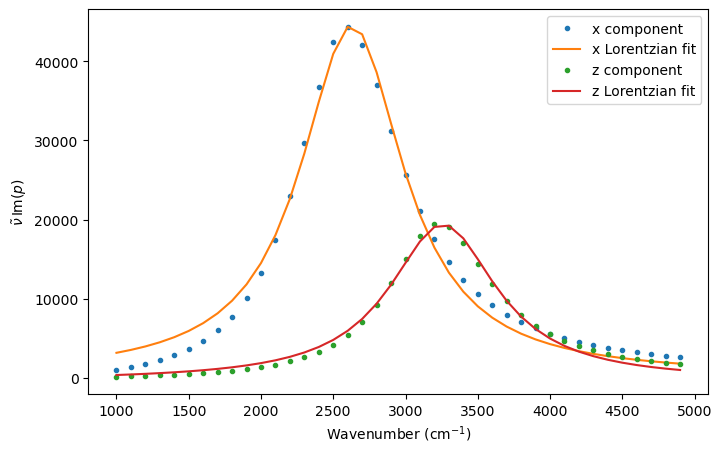

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(x, x_axis_comp, "o", ms=3, label="x component")
plt.plot(x, x_fit, "-", label="x Lorentzian fit")

plt.plot(x, z_axis_comp, "o", ms=3, label="z component")
plt.plot(x, z_fit, "-", label="z Lorentzian fit")

plt.xlabel(r"Wavenumber (cm$^{-1}$)")
plt.ylabel(r"$\tilde{\nu}\,\mathrm{Im}(p)$")
plt.legend()

plt.show()

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def lorentzian(x, A, x0, gamma):
    return A * gamma**2 / ((x - x0)**2 + gamma**2)

def two_lorentzian(x,
                   Q0, slope,
                   A1, x01, gamma1,
                   A2, x02, gamma2):

    return (
        Q0 + slope*x
        + lorentzian(x, A1, x01, gamma1)
        + lorentzian(x, A2, x02, gamma2)
    )
p0 = [
    0.0, 0.0,       # background
    1.0, 2500, 300, # peak 1: amplitude, center, HWHM
    0.5, 4000, 100  # peak 2
]

bounds = (
    [
        -np.inf, -np.inf,
        0, 100, 1,
        0, 100, 1
    ],
    [
        np.inf, np.inf,
        np.inf, 8000, 5000,
        np.inf, 8000, 5000
    ]
)

popt, pcov = curve_fit(
    two_lorentzian,
    light_freq_list, cdm.extinction_efficiency,
    p0=p0,
    bounds=bounds,
    maxfev=50000
)

y_fit = two_lorentzian(light_freq_list, *popt)


Peak 1:
center = 2569.66 cm^-1
FWHM  = 766.26 cm^-1
Q      = 3.35
Peak 2:
center = 3152.74 cm^-1
FWHM  = 1137.01 cm^-1
Q      = 2.77
background ratio is [-5.07935538e+00 -2.61531300e+00 -1.64252710e+00 -1.12571992e+00
 -8.08082772e-01 -5.95375291e-01 -4.44880670e-01 -3.34444882e-01
 -2.51449637e-01 -1.88198116e-01 -1.39747864e-01 -1.02799251e-01
 -7.50808102e-02 -5.49783351e-02 -4.12747669e-02 -3.29185262e-02
 -2.87820484e-02 -2.74717081e-02 -2.73972516e-02 -2.72432994e-02
 -2.64843277e-02 -2.53413806e-02 -2.42475398e-02 -2.34071949e-02
 -2.26937913e-02 -2.17387680e-02 -2.00462881e-02 -1.70755829e-02
 -1.22921629e-02 -5.20145041e-03  4.62545494e-03  1.75296301e-02
  3.37452360e-02  5.33848301e-02  7.64310659e-02  1.02736483e-01
  1.32032193e-01  1.63945046e-01  1.98021636e-01  2.33756579e-01]


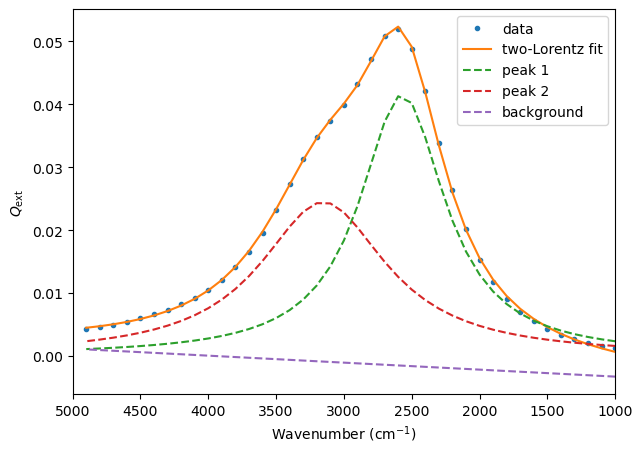

In [72]:
Q0, slope, A1, x01, gamma1, A2, x02, gamma2 = popt

print("Peak 1:")
print(f"center = {x01:.2f} cm^-1")
print(f"FWHM  = {2*gamma1:.2f} cm^-1")
print(f"Q      = {x01/(2*gamma1):.2f}")

print("Peak 2:")
print(f"center = {x02:.2f} cm^-1")
print(f"FWHM  = {2*gamma2:.2f} cm^-1")
print(f"Q      = {x02/(2*gamma2):.2f}")
plt.figure(figsize=(7,5))

plt.plot(light_freq_list, cdm.extinction_efficiency, "o", ms=3, label="data")
plt.plot(light_freq_list, y_fit, "-", label="two-Lorentz fit")

peak1 = lorentzian(light_freq_list, A1, x01, gamma1)
peak2 = lorentzian(light_freq_list, A2, x02, gamma2)
background = Q0 + slope*light_freq_list
print(f"background ratio is {background/y_fit}")
plt.plot(light_freq_list, peak1, "--", label="peak 1")
plt.plot(light_freq_list, peak2, "--", label="peak 2")
plt.plot(light_freq_list,background,"--",label="background")
plt.xlabel(r"Wavenumber (cm$^{-1}$)")
plt.ylabel(r"$Q_{\rm ext}$")
plt.legend()
plt.xlim(5000,1000)
plt.show()

In [ ]:
peak_ratio = p1/p2

In [62]:
np.linalg.linalg.norm(cdm.dips,axis=2).shape

(40, 1)

In [10]:
import sympy as sp

# Symbols
k1, n2, d = sp.symbols('k1 n2 d', positive=True, real=True)

k2 = n2 * k1

# Boundary-condition matrix
A = sp.Matrix([
    [-1,  1,                         1,                          0],
    [ k1, k2,                       -k2,                         0],
    [ 0,  sp.exp(sp.I*k2*d),         sp.exp(-sp.I*k2*d),       -1],
    [ 0,  k2*sp.exp(sp.I*k2*d),     -k2*sp.exp(-sp.I*k2*d),    -k1]
])

# Incident field
E0 = sp.Matrix([
    1,
    k1,
    0,
    0
])

# Solve A E' = E0
E_prime = A.LUsolve(E0)

# Extract coefficients
r = sp.simplify(E_prime[0])
A_forward = sp.simplify(E_prime[1])
A_backward = sp.simplify(E_prime[2])
t = sp.simplify(E_prime[3])

print("r =")
sp.pprint(r)

print("\nt =")
sp.pprint(t)

r =
                2  2⋅ⅈ⋅d⋅k₁⋅n₂     2    2⋅ⅈ⋅d⋅k₁⋅n₂                 
            - n₂ ⋅ℯ            + n₂  + ℯ            - 1             
────────────────────────────────────────────────────────────────────
  2  2⋅ⅈ⋅d⋅k₁⋅n₂     2         2⋅ⅈ⋅d⋅k₁⋅n₂           2⋅ⅈ⋅d⋅k₁⋅n₂    
n₂ ⋅ℯ            - n₂  - 2⋅n₂⋅ℯ            - 2⋅n₂ + ℯ            - 1

t =
                                   ⅈ⋅d⋅k₁⋅n₂                             
                             4⋅n₂⋅ℯ                                      
─────────────────────────────────────────────────────────────────────────
               2⋅ⅈ⋅d⋅k₁⋅n₂                                2⋅ⅈ⋅d⋅k₁⋅n₂    
- n₂⋅(n₂ - 1)⋅ℯ            + n₂⋅(n₂ + 1) + n₂ + (n₂ - 1)⋅ℯ            + 1


In [14]:
t = sp.simplify(E_prime[3])

t = sp.factor(t)
t = sp.powsimp(t, force=True)
t = sp.simplify(t)

r12 = (k1 - k2)/(k1 + k2)
t12 = 2*k1/(k1 + k2)
t23 = 2*k2/(k1 + k2)

t_FP = (
    t12 * t23 * sp.exp(sp.I*k2*d)
    / (1 - r12**2 * sp.exp(2*sp.I*k2*d))
)

sp.simplify(t - t_FP)

0

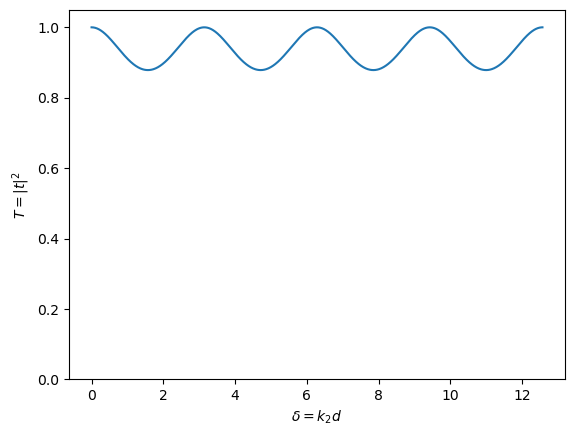

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Symbol
delta = sp.symbols('delta', real=True)

# Refractive index
n2_value = np.sqrt(2.07)

# Fabry-Perot transmission amplitude
t = (
    4 * n2_value * sp.exp(sp.I * delta)
    / (
        (1 + n2_value)**2
        - (1 - n2_value)**2 * sp.exp(2 * sp.I * delta)
    )
)

# Convert symbolic expression to numerical function
t_func = sp.lambdify(delta, t, 'numpy')

# delta values
delta_values = np.linspace(0, 4*np.pi, 1000)

# evaluate
t_values = t_func(delta_values)

# Transmission
T_values = np.abs(t_values)**2

plt.plot(delta_values, T_values)
plt.xlabel(r'$\delta = k_2 d$')
plt.ylabel(r'$T=|t|^2$')
plt.ylim(0, 1.05)
plt.show()

In [28]:
E_rtm = 1j*k_dimensionless_list/(2*lattice_constant**2*(np.sqrt(3)/2))*(cdm.dips[:,0,0]+cdm.dips[:,0,2]*np.tan(incident_theta))

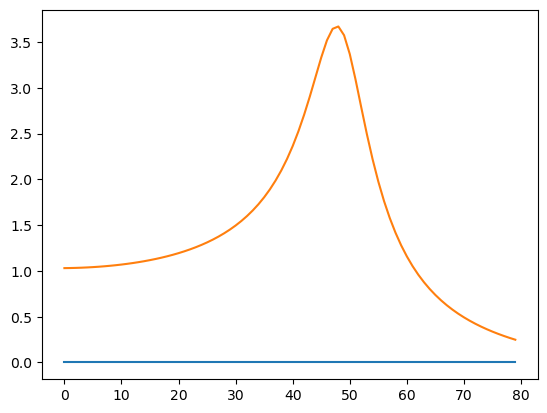

In [29]:
plt.plot(np.abs(cdm.dips[:,0,2]))
plt.plot(np.abs(cdm.dips[:,0,0]))

In [30]:
k_dimensionless_list

array([0.00042323, 0.00084647, 0.0012697 , 0.00169294, 0.00211617,
       0.0025394 , 0.00296264, 0.00338587, 0.0038091 , 0.00423234,
       0.00465557, 0.00507881, 0.00550204, 0.00592527, 0.00634851,
       0.00677174, 0.00719497, 0.00761821, 0.00804144, 0.00846468,
       0.00888791, 0.00931114, 0.00973438, 0.01015761, 0.01058084,
       0.01100408, 0.01142731, 0.01185055, 0.01227378, 0.01269701,
       0.01312025, 0.01354348, 0.01396672, 0.01438995, 0.01481318,
       0.01523642, 0.01565965, 0.01608288, 0.01650612, 0.01692935,
       0.01735259, 0.01777582, 0.01819905, 0.01862229, 0.01904552,
       0.01946875, 0.01989199, 0.02031522, 0.02073846, 0.02116169,
       0.02158492, 0.02200816, 0.02243139, 0.02285462, 0.02327786,
       0.02370109, 0.02412433, 0.02454756, 0.02497079, 0.02539403,
       0.02581726, 0.0262405 , 0.02666373, 0.02708696, 0.0275102 ,
       0.02793343, 0.02835666, 0.0287799 , 0.02920313, 0.02962637,
       0.0300496 , 0.03047283, 0.03089607, 0.0313193 , 0.03174